&nbsp;

&nbsp;

# HN-score transcript up5p selection

- [./02_1_HNscore_transcript_fantabio.ipynb](./02_1_HNscore_transcript_fantabio.ipynb) で、全ての HN-score を算出した transcript と CRE の対応を作成したので、これを元に、up5p に対応する transcript-cre を選抜する

In [1]:
import os
import datetime
import pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import polars as pl
import matplotlib.pyplot as plt
from upsetplot import UpSet, from_contents
from IPython.display import display


os.environ["POLARS_MAX_THREADS"] = "16"

In [2]:
VERSION = datetime.datetime.now().strftime("%y%m")
Execute_date = datetime.datetime.now().strftime("%y%m%d")
print(f"Execute Date: {Execute_date}")

Execute Date: 261001


&nbsp;

&nbsp;

&nbsp;

## 1． All HN-score calculated Transcript - CRE pairs

- 公共遺伝子発現データ (bulk RNA-seq) のメタ解析 によって得られた transcriptsのデータを使用する
- このデータには、CRE と対応づいていない transcript も含まれていることに注意
- [./02_1_HNscore_transcript_fantabio.ipynb](./02_1_HNscore_transcript_fantabio.ipynb) によって作成した対応表を使用する

In [3]:
HNscore_transcript_all_fantabio = pl.read_parquet(
    f"../../out/fantabio/parquet_file/HNscore_transcript_all_fantabio_v261001.parquet"
)

pl.Config.set_tbl_rows(4)
display(HNscore_transcript_all_fantabio)

transcript_id,UP2,DOWN2,UNCHANGED2,HN2,UP2_stranded,DOWN2_stranded,UNCHANGED2_stranded,HN2_stranded,gene_symbol,HGNC_ID,transcript_type,gene_id,tags,strand,number_of_tags,RNACentral_ID,corrrespondence,polyA_features,gene_source,annotation_remarks,annotation_remark_count,cre_id,cre_chrom,cre_chrom_start,cre_chrom_end,cre_name,tss_nearest_transcript_ids,tss_nearest_transcript_distance,transcript_distance,screen_ccres,chip_atlas_antigens,silencerdbs,fantom5_cage_peaks,fantom5_enhancers,directionality,fantabio_cre_class,itemRgb,itemRgb_name
str,i64,i64,i64,i64,i64,i64,i64,i64,str,str,str,str,list[str],str,u32,str,str,list[str],str,list[str],u32,str,str,i64,str,str,list[str],str,i64,list[struct[2]],list[struct[3]],list[struct[5]],list[struct[2]],list[struct[1]],f64,str,str,str
"""ENST00000309758.6""",352,17,37,335,232,4,15,228,"""HSPA6""","""HGNC:5239""","""protein_coding""","""ENSG00000173110.8""","[""basic"", ""Ensembl_canonical"", … ""CCDS""]","""+""",6,null,null,null,"""ensembl_havana_gene_homo_sapie…","[""MANE_select""]",1,"""FCHS_28105""","""chr1""",161523745,"""161524487""","""cp1@HSPA6""","[""GQ891451""]","""0""",53,"[{""EH38E2843853"",""pELS""}, {""EH38E2843855"",""PLS""}, {""EH38E3981533"",""pELS""}]","[{""STAG2"",4103,[{""SRX9975614"",4103}, {""SRX9975613"",3500}, {""SRX26159208"",562}]}, {""HSF1"",4038,[{""SRX16646095"",4038}, {""SRX16646111"",3572}, … {""SRX13845684"",554}]}, … {""GABPA"",500,[{""SRX2635792"",500}]}]","[{""HS_00013400"",""H1 BMP4 Derived Mesendoderm Cultured Cells"",""Mesendoderm cell"",""Others"",""SVM""}, {""HS_00013401"",""H1 Cells"",""Embryonic stem cell"",""Stem cell"",""SVM""}, … {""HS_00013403"",""Foreskin Fibroblast Primary Cells skin02"",""Prepuce"",""Skin"",""SVM""}]",null,null,0.982111,"""PLA""","""204,0,0""","""red"""
"""ENST00000309758.6""",352,17,37,335,232,4,15,228,"""HSPA6""","""HGNC:5239""","""protein_coding""","""ENSG00000173110.8""","[""basic"", ""Ensembl_canonical"", … ""CCDS""]","""+""",6,null,null,null,"""ensembl_havana_gene_homo_sapie…","[""MANE_select""]",1,"""FCHS_28106""","""chr1""",161524161,"""161524546""","""cp4@HSPA6""","[""ENST00000309758.6"", ""NM_002155.5"", … ""AK295212""]","""0""",0,"[{""EH38E2843855"",""PLS""}]","[{""HSF1"",4038,[{""SRX16646095"",4038}, {""SRX16646111"",3572}, … {""SRX3322007"",560}]}, {""CTCF"",3651,[{""SRX10975999"",3651}, {""SRX10976007"",2920}, … {""SRX13551280"",511}]}, … {""MED12"",511,[{""SRX10852993"",511}]}]","[{""HS_00013400"",""H1 BMP4 Derived Mesendoderm Cultured Cells"",""Mesendoderm cell"",""Others"",""SVM""}, {""HS_00013401"",""H1 Cells"",""Embryonic stem cell"",""Stem cell"",""SVM""}, … {""HS_00013403"",""Foreskin Fibroblast Primary Cells skin02"",""Prepuce"",""Skin"",""SVM""}]","[{""hg19::chr1:161494328..161494332,+;hg_6264.1"",""p1@HSPA6""}]",null,0.943234,"""PLA""","""204,0,0""","""red"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""ENST00000549545.1""",11,265,130,-254,8,174,69,-166,"""COQ10A""","""HGNC:26515""","""retained_intron""","""ENSG00000135469.15""",[],"""+""",0,null,null,null,"""ensembl_havana_gene_homo_sapie…",null,0,"""FCHS_96252""","""chr12""",56268140,"""56268446""","""cp6@COQ10A""","[""ENST00000549545.1""]","""-23""",-23,"[{""EH38E4064794"",""pELS""}]",null,"[{""HS_00173371"",""H1 BMP4 Derived Mesendoderm Cultured Cells"",""Mesendoderm cell"",""Others"",""SVM""}, {""HS_02053667"",""Thyroid Gland"",""Thyroid gland"",""Others"",""gkmSVM""}]",null,null,-0.368421,"""ELA""","""255,202,74""","""yellow"""
"""ENST00000560179.2""",11,272,123,-261,5,181,65,-176,"""ETFA""","""HGNC:3481""","""retained_intron""","""ENSG00000140374.18""","[""RNA_Seq_supported_partial""]","""-""",1,null,null,null,"""ensembl_havana_gene_homo_sapie…","[""RNA-Seq supported partial""]",1,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null


&nbsp;

&nbsp;

&nbsp;

&nbsp;

## 2. up5p transcripts (all datasets)

- related notebook: [../01_HNscore/01_2_HNscore_transcript_gencode.ipynb](../01_HNscore/01_2_HNscore_transcript_gencode.ipynb)
- 収集した全ての bulk RNA-seq から計算した HN-score のデータから選抜したデータを使用する

In [4]:

up5p_transcripts_list = pl.read_csv(
    "../../Data/HNscore/HNscore_transcript/HNscore_gencode_2610/HN2_top_5_percent_transcripts.tsv",
    separator="\t",
    n_threads=16
)


pl.Config.set_tbl_rows(4)
print(up5p_transcripts_list.select("transcript_id").n_unique())
display(up5p_transcripts_list)

26354


transcript_id,UP2,DOWN2,UNCHANGED2,HN2,UPcount+1 / DOWNcount+1 2,log2(UPcount+1 / DOWNcount+1) 2
str,i64,i64,i64,i64,f64,f64
"""ENST00000309758.6""",352,17,37,335,19.611111,4.293599
"""ENST00000679223.2""",338,8,60,330,37.666667,5.235216
…,…,…,…,…,…,…
"""ENST00000797768.1""",92,48,266,44,1.897959,0.924449
"""ENST00000781552.1""",115,71,220,44,1.611111,0.688056


&nbsp;

&nbsp;

&nbsp;

&nbsp;

## 3. `JOIN` Dataframe

In [5]:
up5p_fantabio = up5p_transcripts_list.select("transcript_id").unique().join(
    HNscore_transcript_all_fantabio,
    on="transcript_id",
    how="inner",
    coalesce=True
).sort(
    "HN2",
    descending=True
).filter(
    pl.col("cre_id").is_not_null()
)

pl.Config.set_tbl_rows(2)
print(f"up5p_transcripts_all ensembl transcript count: {up5p_transcripts_list.select('transcript_id').n_unique()}")
print(f"up5p_fantabio ensembl transcript count (has fantabio CRE annotation): {up5p_fantabio.select('transcript_id').n_unique()}")
print(f"up5p_fantabio cre count: {up5p_fantabio.select('cre_id').n_unique()}")
print(f"up5p_fantabio transcript-CRE pairs count: {up5p_fantabio.select(['transcript_id', 'cre_id']).n_unique()}")
display(up5p_fantabio)


up5p_transcripts_all ensembl transcript count: 26354
up5p_fantabio ensembl transcript count (has fantabio CRE annotation): 21696
up5p_fantabio cre count: 33961
up5p_fantabio transcript-CRE pairs count: 63099


transcript_id,UP2,DOWN2,UNCHANGED2,HN2,UP2_stranded,DOWN2_stranded,UNCHANGED2_stranded,HN2_stranded,gene_symbol,HGNC_ID,transcript_type,gene_id,tags,strand,number_of_tags,RNACentral_ID,corrrespondence,polyA_features,gene_source,annotation_remarks,annotation_remark_count,cre_id,cre_chrom,cre_chrom_start,cre_chrom_end,cre_name,tss_nearest_transcript_ids,tss_nearest_transcript_distance,transcript_distance,screen_ccres,chip_atlas_antigens,silencerdbs,fantom5_cage_peaks,fantom5_enhancers,directionality,fantabio_cre_class,itemRgb,itemRgb_name
str,i64,i64,i64,i64,i64,i64,i64,i64,str,str,str,str,list[str],str,u32,str,str,list[str],str,list[str],u32,str,str,i64,str,str,list[str],str,i64,list[struct[2]],list[struct[3]],list[struct[5]],list[struct[2]],list[struct[1]],f64,str,str,str
"""ENST00000309758.6""",352,17,37,335,232,4,15,228,"""HSPA6""","""HGNC:5239""","""protein_coding""","""ENSG00000173110.8""","[""basic"", ""Ensembl_canonical"", … ""CCDS""]","""+""",6,null,null,null,"""ensembl_havana_gene_homo_sapie…","[""MANE_select""]",1,"""FCHS_28105""","""chr1""",161523745,"""161524487""","""cp1@HSPA6""","[""GQ891451""]","""0""",53,"[{""EH38E2843853"",""pELS""}, {""EH38E2843855"",""PLS""}, {""EH38E3981533"",""pELS""}]","[{""STAG2"",4103,[{""SRX9975614"",4103}, {""SRX9975613"",3500}, {""SRX26159208"",562}]}, {""HSF1"",4038,[{""SRX16646095"",4038}, {""SRX16646111"",3572}, … {""SRX13845684"",554}]}, … {""GABPA"",500,[{""SRX2635792"",500}]}]","[{""HS_00013400"",""H1 BMP4 Derived Mesendoderm Cultured Cells"",""Mesendoderm cell"",""Others"",""SVM""}, {""HS_00013401"",""H1 Cells"",""Embryonic stem cell"",""Stem cell"",""SVM""}, … {""HS_00013403"",""Foreskin Fibroblast Primary Cells skin02"",""Prepuce"",""Skin"",""SVM""}]",null,null,0.982111,"""PLA""","""204,0,0""","""red"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""ENST00000774581.1""",101,57,248,44,34,44,173,-10,null,null,"""lncRNA""","""ENSG00000300853.1""","[""basic"", ""TAGENE""]","""+""",2,"""URS0002A25289""","""ENSEMBL_GENCODE""",null,"""havana_tagene_homo_sapiens""","[""CLS3 project""]",1,"""FCHS_400104""","""chr8""",27592922,"""27593122""","""FCHS_400104""","[""ENST00000774579.1""]","""0""",294,"[{""EH38E3824983"",""dELS""}]",null,"[{""HS_00105821"",""NHEK-Epidermal Keratinocyte Primary Cells"",""Skin"",""Skin"",""SVM""}, {""HS_00105822"",""H1 BMP4 Derived Trophoblast Cultured Cells"",""Trophoblast cell"",""Others"",""SVM""}, … {""HS_00105828"",""Breast variant Human Mammary Epithelial Cells (vHMEC)"",""Breast"",""Breast"",""SVM""}]",null,null,0.5,"""ELA""","""255,202,74""","""yellow"""


In [6]:
up5p_fantabio.write_parquet(
    f"../../out/fantabio/parquet_file/up5p_transcript_fantabio_v{Execute_date}.parquet",
    compression_level=9
)

In [7]:
# check
HSPA1B = up5p_fantabio.filter(pl.col("gene_symbol") == "HSPA1B")
display(HSPA1B)


transcript_id,UP2,DOWN2,UNCHANGED2,HN2,UP2_stranded,DOWN2_stranded,UNCHANGED2_stranded,HN2_stranded,gene_symbol,HGNC_ID,transcript_type,gene_id,tags,strand,number_of_tags,RNACentral_ID,corrrespondence,polyA_features,gene_source,annotation_remarks,annotation_remark_count,cre_id,cre_chrom,cre_chrom_start,cre_chrom_end,cre_name,tss_nearest_transcript_ids,tss_nearest_transcript_distance,transcript_distance,screen_ccres,chip_atlas_antigens,silencerdbs,fantom5_cage_peaks,fantom5_enhancers,directionality,fantabio_cre_class,itemRgb,itemRgb_name
str,i64,i64,i64,i64,i64,i64,i64,i64,str,str,str,str,list[str],str,u32,str,str,list[str],str,list[str],u32,str,str,i64,str,str,list[str],str,i64,list[struct[2]],list[struct[3]],list[struct[5]],list[struct[2]],list[struct[1]],f64,str,str,str
"""ENST00000375650.5""",298,12,96,286,198,2,51,196,"""HSPA1B""","""HGNC:5233""","""protein_coding""","""ENSG00000204388.7""","[""basic"", ""Ensembl_canonical"", … ""CCDS""]","""+""",6,null,null,"[""polya_signal"", ""polya_site""]","""ensembl_havana_gene_homo_sapie…","[""MANE_select""]",1,"""FCHS_354485""","""chr6""",31826812,"""31827243""","""FCHS_354485""","[""ENST00000700791.2""]","""-200""",495,"[{""EH38E3700980"",""pELS""}]","[{""SOX10"",1998,[{""SRX13340348"",1998}, {""SRX13340342"",1533}, … {""SRX13340334"",1145}]}, {""STAT3"",1988,[{""SRX5323888"",1988}, {""SRX5323892"",1950}, … {""SRX5323838"",1456}]}, … {""CPSF3L"",505,[{""SRX9730737"",505}]}]",null,"[{""hg19::chr6:31794677..31794710,-;hg_72844.1"",""hg_72844.1""}, {""hg19::chr6:31795013..31795063,-;hg_72845.1"",""hg_72845.1""}]",null,-0.869084,"""PLA""","""0,0,204""","""blue"""
"""ENST00000375650.5""",298,12,96,286,198,2,51,196,"""HSPA1B""","""HGNC:5233""","""protein_coding""","""ENSG00000204388.7""","[""basic"", ""Ensembl_canonical"", … ""CCDS""]","""+""",6,null,null,"[""polya_signal"", ""polya_site""]","""ensembl_havana_gene_homo_sapie…","[""MANE_select""]",1,"""FCHS_354486""","""chr6""",31827058,"""31827936""","""cp1@HSPA1A,cp1@HSPA1B""","[""ENST00000375650.5"", ""NM_005346.6"", … ""BC009322""]","""0""",0,"[{""EH38E3700980"",""pELS""}, {""EH38E3700981"",""pELS""}, {""EH38E3700982"",""PLS""}]","[{""RFX1"",4363,[{""SRX2423398"",4363}, {""SRX2423399"",4127}, … {""SRX5457513"",1773}]}, {""HSF1"",4055,[{""SRX16646102"",4055}, {""SRX16646094"",3769}, … {""SRX8512780"",500}]}, … {""MYF5"",500,[{""SRX1962094"",500}]}]",null,"[{""hg19::chr6:31795013..31795063,-;hg_72845.1"",""hg_72845.1""}, {""hg19::chr6:31795123..31795151,-;hg_72846.1"",""hg_72846.1""}, … {""hg19::chr6:31795506..31795525,+;hg_67062.1"",""p2@HSPA1B""}]",null,0.997399,"""PLA""","""204,0,0""","""red"""


&nbsp;

&nbsp;

&nbsp;

&nbsp;

## 4. No Proximal CRE Transcripts

- fanta.bio CRE annotation (± 500 bp) がない transcript を取得

In [8]:
# fanta.bio CRE annotation (± 500 bp) がない transcript を可視化
up5p_fantabio_no_cre = up5p_transcripts_list.select("transcript_id").unique().join(
    HNscore_transcript_all_fantabio,
    on="transcript_id",
    how="inner",
    coalesce=True
).sort(
    "HN2",
    descending=True
).filter(
    pl.col("cre_id").is_null() # Point: 近傍に fantabio CRE がない
)

# Drop columns that are null on every row (CRE fields stay null when cre_id is null)
up5p_fantabio_no_cre = up5p_fantabio_no_cre.select(
    [
        name
        for name, n_null in zip(
            up5p_fantabio_no_cre.columns,
            up5p_fantabio_no_cre.null_count().row(0),
        )
        if n_null < up5p_fantabio_no_cre.height
    ]
)

up5p_fantabio_no_cre.write_parquet(
    f"../../out/fantabio/no_proximal_cre_transcirpt_list/up5p_transcript_no_cre_v{Execute_date}.parquet",
    compression_level=9
)

display(up5p_fantabio_no_cre)

transcript_id,UP2,DOWN2,UNCHANGED2,HN2,UP2_stranded,DOWN2_stranded,UNCHANGED2_stranded,HN2_stranded,gene_symbol,HGNC_ID,transcript_type,gene_id,tags,strand,number_of_tags,RNACentral_ID,corrrespondence,polyA_features,gene_source,annotation_remarks,annotation_remark_count
str,i64,i64,i64,i64,i64,i64,i64,i64,str,str,str,str,list[str],str,u32,str,str,list[str],str,list[str],u32
"""ENST00000450744.1""",335,13,58,322,223,4,24,219,"""HSPA1B""","""HGNC:5233""","""protein_coding""","""ENSG00000232804.5""","[""basic""]","""+""",1,null,null,null,"""ensembl_havana_gene_homo_sapie…",null,0
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""ENST00000846985.1""",72,28,306,44,4,5,242,-1,"""PKP4-AS1""","""HGNC:52580""","""lncRNA""","""ENSG00000204380.5""","[""basic"", ""Ensembl_canonical"", … ""TAGENE""]","""-""",4,"""URS0002A3DDE3""","""ENSEMBL_GENCODE""",null,"""havana_homo_sapiens""","[""CLS3 project""]",1


&nbsp;

&nbsp;

&nbsp;

&nbsp;

## 5. `ChIP-Atlas` Enrichment analysis で実行する用のBEDファイル作成

In [9]:
# https://data.fanta.bio/cre/v1.2.1/00README_v1.2.1.txt
fantabio_bed = pl.read_csv(
    "../../Data/Database/fantabio/human-CREv1.2.1.hg38.cre-peaks.bed",
    separator="\t",
    n_threads=16,
    has_header=False,
    new_columns=[
        "cre_chrom",
        "cre_chrom_start",
        "cre_chrom_end",
        "cre_id",
        "score",
        "strand",
        "thickStart",
        "thickEnd",
        "itemRgb",
        "cre_name",
        "pooled_cre_scores"
    ]
).with_columns(
    pl.col("pooled_cre_scores").str.extract(r"directionality:([^|]+)", 1).cast(pl.Float64, strict=False).alias("directionality"),
    pl.col("pooled_cre_scores").str.extract(r"class:([^|]+)", 1).alias("fantabio_cre_class"),
)

# Map exact RGB strings to human-readable names
rgb_to_name = {
    "153,0,0": "dark_red",
    "101,0,0": "dark_red",
    "50,0,0": "dark_red",
    "204,0,0": "red",
    "255,0,0": "red",
    "0,0,51": "dark_blue",
    "0,0,102": "dark_blue",
    "0,0,153": "blue",
    "0,0,204": "blue",
    "0,0,255": "blue",
    "0,0,0": "black",
    "255,202,74": "yellow",
}

fantabio_bed_select = fantabio_bed.with_columns(
    pl.col("itemRgb").replace_strict(
        rgb_to_name,
        default="other"
    ).alias("itemRgb_name")
).select(
    "cre_id",
    "cre_name",
    "directionality",
    "fantabio_cre_class",
    "itemRgb",
    "itemRgb_name"
)

display(fantabio_bed_select)

cre_id,cre_name,directionality,fantabio_cre_class,itemRgb,itemRgb_name
str,str,f64,str,str,str
"""FCHS_1""","""cp1@DDX11L1""",-1.0,"""PLA""","""0,0,255""","""blue"""
…,…,…,…,…,…
"""FCHS_593940""","""FCHS_593940""",0.989305,"""PLA""","""204,0,0""","""red"""


&nbsp;

&nbsp;

## 5-1: All CRE

- ChIP-Analysis Enrichment Analysis で使用するBEDファイルは、全ての transcript (up5p かつ、近傍に `fanta.bio` で定義されたCREが存在すること) のみを対象にすることにした

In [10]:
up5p_fantabio_bed = fantabio_bed.join(
    up5p_fantabio.select("cre_id").unique(),
    on="cre_id",
    how="semi"
)

print(f"up5p_fantabio_bed count: {up5p_fantabio_bed.select('cre_id').n_unique()}")
display(up5p_fantabio_bed)

up5p_fantabio_bed count: 33961


cre_chrom,cre_chrom_start,cre_chrom_end,cre_id,score,strand,thickStart,thickEnd,itemRgb,cre_name,pooled_cre_scores,directionality,fantabio_cre_class
str,i64,i64,str,i64,str,i64,i64,str,str,str,f64,str
"""chr1""",29398,29439,"""FCHS_2""",0,""".""",29398,29432,"""255,202,74""","""cp1@WASH7P""","""directionality:1|class:ELA""",1.0,"""ELA"""
…,…,…,…,…,…,…,…,…,…,…,…,…
"""chrY""",19076394,19076956,"""FCHS_447245""",0,""".""",19076666,19076785,"""255,202,74""","""cp5@TTTY14""","""directionality:0.777778|class:…",0.777778,"""ELA"""


&nbsp;

&nbsp;

## 5-2: Promoter Level Activity (PLA) CRE

In [11]:
up5p_fantabio_bed_pla = up5p_fantabio_bed.filter(
    pl.col("fantabio_cre_class") == "PLA"
)

up5p_fantabio_bed_pla.select(
    "cre_chrom",
    "cre_chrom_start",
    "cre_chrom_end"
).write_csv(
    f"../../out/fantabio/BEDfile/up5p/fantabio_up5p_all_pla_v{Execute_date}.bed",
    include_header=False,
    separator="\t"
)

print(f"up5p_fantabio_bed_pla count: {up5p_fantabio_bed_pla.select('cre_id').n_unique()}")
display(up5p_fantabio_bed_pla)

up5p_fantabio_bed_pla count: 14620


cre_chrom,cre_chrom_start,cre_chrom_end,cre_id,score,strand,thickStart,thickEnd,itemRgb,cre_name,pooled_cre_scores,directionality,fantabio_cre_class
str,i64,i64,str,i64,str,i64,i64,str,str,str,f64,str
"""chr1""",778536,778928,"""FCHS_19""",0,""".""",778631,778800,"""0,0,51""","""cp5@LINC00115,cp2@LINC01409""","""directionality:-0.304838|class…",-0.304838,"""PLA"""
…,…,…,…,…,…,…,…,…,…,…,…,…
"""chrY""",19075819,19076450,"""FCHS_447243""",0,""".""",19076001,19076187,"""0,0,204""","""cp4@TTTY14""","""directionality:-0.890534|class…",-0.890534,"""PLA"""


&nbsp;

&nbsp;

## 5-3: Enhancer Level Activity (ELA) CRE

In [12]:
up5p_fantabio_bed_ela = up5p_fantabio_bed.filter(
    pl.col("fantabio_cre_class") == "ELA"
)

up5p_fantabio_bed_ela.select(
    "cre_chrom",
    "cre_chrom_start",
    "cre_chrom_end"
).write_csv(
    f"../../out/fantabio/BEDfile/up5p/fantabio_up5p_all_ela_v{Execute_date}.bed",
    include_header=False,
    separator="\t"
)

print(f"up5p_fantabio_bed_ela count: {up5p_fantabio_bed_ela.select('cre_id').n_unique()}")
display(up5p_fantabio_bed_ela)

up5p_fantabio_bed_ela count: 19341


cre_chrom,cre_chrom_start,cre_chrom_end,cre_id,score,strand,thickStart,thickEnd,itemRgb,cre_name,pooled_cre_scores,directionality,fantabio_cre_class
str,i64,i64,str,i64,str,i64,i64,str,str,str,f64,str
"""chr1""",29398,29439,"""FCHS_2""",0,""".""",29398,29432,"""255,202,74""","""cp1@WASH7P""","""directionality:1|class:ELA""",1.0,"""ELA"""
…,…,…,…,…,…,…,…,…,…,…,…,…
"""chrY""",19076394,19076956,"""FCHS_447245""",0,""".""",19076666,19076785,"""255,202,74""","""cp5@TTTY14""","""directionality:0.777778|class:…",0.777778,"""ELA"""


&nbsp;

&nbsp;

&nbsp;

&nbsp;

&nbsp;

&nbsp;

&nbsp;

&nbsp;

## 6. Distance Servey

&nbsp;

&nbsp;

## 6-1. upregulated transcript-CRE distance

- ここで可視化しているのは、メタ解析で取得した全てのtranscript の分布

In [13]:
# このデータフレームの行数 = transcript - CRE pair count になる
up5p_fantabio_cre_distance = up5p_fantabio.select(
    "transcript_id",
    "cre_id",
    "cre_name",
    "fantabio_cre_class",
    "transcript_distance"
).with_columns(
    pl.col("transcript_distance").abs().alias("transcript_distance_abs") # Point: 絶対値に変換
).unique()

display(up5p_fantabio_cre_distance)

transcript_id,cre_id,cre_name,fantabio_cre_class,transcript_distance,transcript_distance_abs
str,str,str,str,i64,i64
"""ENST00000650301.1""","""FCHS_166170""","""cp9@DLG4""","""ELA""",254,254
…,…,…,…,…,…
"""ENST00000284274.5""","""FCHS_325708""","""cp4@OTULIN-DT""","""ELA""",300,300


In [14]:
plot_df = up5p_fantabio_cre_distance.to_pandas()

# 5 bins: 0-100, 101-200, ..., 401-500
bin_edges = [0, 101, 201, 301, 401, 501]
bin_labels = ["0-100", "101-200", "201-300", "301-400", "401-500"]

plot_df["distance_bin"] = pd.cut(
    plot_df["transcript_distance_abs"],
    bins=bin_edges,
    labels=bin_labels,
    right=False,
    include_lowest=True,
)

count_df = (
    plot_df.groupby(["distance_bin", "fantabio_cre_class"], observed=True)
    .size()
    .to_frame("count")
    .reset_index()
)

pivot_df = (
    count_df.pivot(index="distance_bin", columns="fantabio_cre_class", values="count")
    .fillna(0)
    .astype(int)
    .reindex(bin_labels)
)

classes = pivot_df.columns.tolist()
palette = sns.color_palette("Set2", n_colors=len(classes))
color_map = dict(zip(classes, palette))

sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(16, 10))

bottom = np.zeros(len(pivot_df))
x = np.arange(len(pivot_df.index))

for cls in classes:
    heights = pivot_df[cls].to_numpy()
    ax.bar(
        x,
        heights,
        bottom=bottom,
        label=cls,
        color=color_map[cls],
        edgecolor="white",
        linewidth=0.5,
    )
    bottom += heights

ax.set_xticks(x)
ax.set_xticklabels(pivot_df.index, fontsize=14)
ax.set_xlabel("|transcript distance| bin (bp)", fontsize=18)
ax.set_ylabel("Count (transcript–CRE pairs)", fontsize=18)
ax.set_title("100 bp bins by up5p transcript-fantabio CRE class", fontsize=18)
ax.legend(title="fantabio CRE class", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.tick_params(axis="y", labelsize=14)

plt.tight_layout()
plt.show()

<Figure size 1600x1000 with 1 Axes>

&nbsp;

&nbsp;

## 6-2: up5p lncRNA-CRE distance

- lncRNA only

In [15]:
# 一旦 lncRNA のみに絞る
up5p_lncRNA_fantabio = up5p_fantabio.filter(
    (pl.col("transcript_type") == "lncRNA")
).sort(
    "HN2",
    descending=True
)

print(f"up5p_lncRNA_fantabio ensembl transcript count: {up5p_lncRNA_fantabio.select('transcript_id').n_unique()}")
print(f"up5p_lncRNA_fantabio transcript-CRE pairs count: {up5p_lncRNA_fantabio.select(['transcript_id', 'cre_id']).n_unique()}")
display(up5p_lncRNA_fantabio)

up5p_lncRNA_fantabio ensembl transcript count: 3657
up5p_lncRNA_fantabio transcript-CRE pairs count: 9221


transcript_id,UP2,DOWN2,UNCHANGED2,HN2,UP2_stranded,DOWN2_stranded,UNCHANGED2_stranded,HN2_stranded,gene_symbol,HGNC_ID,transcript_type,gene_id,tags,strand,number_of_tags,RNACentral_ID,corrrespondence,polyA_features,gene_source,annotation_remarks,annotation_remark_count,cre_id,cre_chrom,cre_chrom_start,cre_chrom_end,cre_name,tss_nearest_transcript_ids,tss_nearest_transcript_distance,transcript_distance,screen_ccres,chip_atlas_antigens,silencerdbs,fantom5_cage_peaks,fantom5_enhancers,directionality,fantabio_cre_class,itemRgb,itemRgb_name
str,i64,i64,i64,i64,i64,i64,i64,i64,str,str,str,str,list[str],str,u32,str,str,list[str],str,list[str],u32,str,str,i64,str,str,list[str],str,i64,list[struct[2]],list[struct[3]],list[struct[5]],list[struct[2]],list[struct[1]],f64,str,str,str
"""ENST00000850140.1""",317,6,83,311,207,2,42,205,null,null,"""lncRNA""","""ENSG00000310471.1""","[""basic"", ""Ensembl_canonical"", … ""TAGENE""]","""+""",4,"""URS0002A15385""","""ENSEMBL_GENCODE""",null,"""havana_tagene_homo_sapiens""","[""CLS3 project"", ""overlaps pseudogene""]",2,"""FCHS_28129""","""chr1""",161605881,"""161606178""","""cp1@HSPA7""","[""NR_024151.2""]","""0""",0,"[{""EH38E2843898"",""pELS""}]","[{""CTCF"",1775,[{""SRX10975999"",1775}, {""SRX10976007"",1383}, … {""SRX10976004"",607}]}, {""BCOR"",952,[{""SRX10382399"",952}, {""SRX10382441"",932}]}, … {""PTEN"",504,[{""SRX5416007"",504}]}]","[{""HS_00013426"",""H1 Cells"",""Embryonic stem cell"",""Stem cell"",""SVM""}]","[{""hg19::chr1:161575959..161575964,+;hg_6268.1"",""p1@HSPA7""}]",null,1.0,"""ELA""","""255,202,74""","""yellow"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""ENST00000774581.1""",101,57,248,44,34,44,173,-10,null,null,"""lncRNA""","""ENSG00000300853.1""","[""basic"", ""TAGENE""]","""+""",2,"""URS0002A25289""","""ENSEMBL_GENCODE""",null,"""havana_tagene_homo_sapiens""","[""CLS3 project""]",1,"""FCHS_400104""","""chr8""",27592922,"""27593122""","""FCHS_400104""","[""ENST00000774579.1""]","""0""",294,"[{""EH38E3824983"",""dELS""}]",null,"[{""HS_00105821"",""NHEK-Epidermal Keratinocyte Primary Cells"",""Skin"",""Skin"",""SVM""}, {""HS_00105822"",""H1 BMP4 Derived Trophoblast Cultured Cells"",""Trophoblast cell"",""Others"",""SVM""}, … {""HS_00105828"",""Breast variant Human Mammary Epithelial Cells (vHMEC)"",""Breast"",""Breast"",""SVM""}]",null,null,0.5,"""ELA""","""255,202,74""","""yellow"""


In [16]:
# このデータフレームの行数 = lncRNA - CRE pair count になる
up5p_lncRNA_fantabio_cre_distance = up5p_lncRNA_fantabio.select(
    "transcript_id",
    "cre_id",
    "cre_name",
    "fantabio_cre_class",
    "transcript_distance"
).with_columns(
    pl.col("transcript_distance").abs().alias("transcript_distance_abs") # Point: 絶対値に変換
).unique()

display(up5p_lncRNA_fantabio_cre_distance)

transcript_id,cre_id,cre_name,fantabio_cre_class,transcript_distance,transcript_distance_abs
str,str,str,str,i64,i64
"""ENST00000746849.1""","""FCHS_490814""","""cp5@LOC105370787""","""PLA""",0,0
…,…,…,…,…,…
"""ENST00000673878.1""","""FCHS_230904""","""cp5@MIR4435-2HG""","""PLA""",0,0


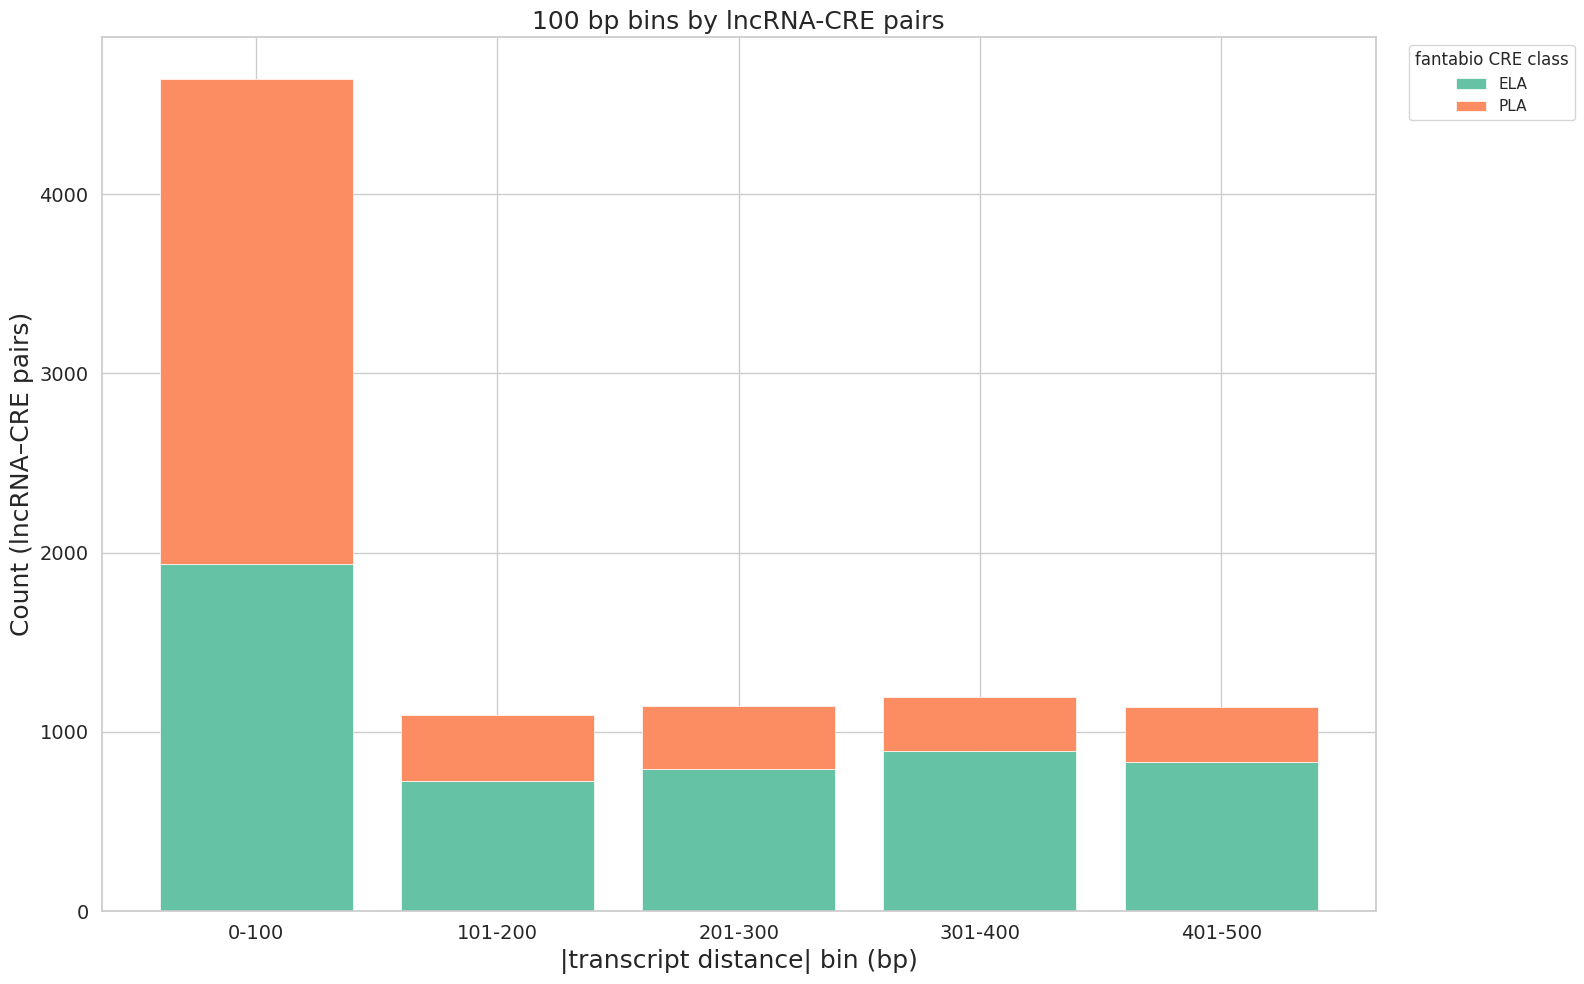

In [17]:
plot_df = up5p_lncRNA_fantabio_cre_distance.to_pandas()

# 5 bins: 0-100, 101-200, ..., 401-500
bin_edges = [0, 101, 201, 301, 401, 501]
bin_labels = ["0-100", "101-200", "201-300", "301-400", "401-500"]

plot_df["distance_bin"] = pd.cut(
    plot_df["transcript_distance_abs"],
    bins=bin_edges,
    labels=bin_labels,
    right=False,
    include_lowest=True,
)

count_df = (
    plot_df.groupby(["distance_bin", "fantabio_cre_class"], observed=True)
    .size()
    .to_frame("count")
    .reset_index()
)

pivot_df = (
    count_df.pivot(index="distance_bin", columns="fantabio_cre_class", values="count")
    .fillna(0)
    .astype(int)
    .reindex(bin_labels)
)

classes = pivot_df.columns.tolist()
palette = sns.color_palette("Set2", n_colors=len(classes))
color_map = dict(zip(classes, palette))

sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(16, 10))

bottom = np.zeros(len(pivot_df))
x = np.arange(len(pivot_df.index))

for cls in classes:
    heights = pivot_df[cls].to_numpy()
    ax.bar(
        x,
        heights,
        bottom=bottom,
        label=cls,
        color=color_map[cls],
        edgecolor="white",
        linewidth=0.5,
    )
    bottom += heights

ax.set_xticks(x)
ax.set_xticklabels(pivot_df.index, fontsize=14)
ax.set_xlabel("|transcript distance| bin (bp)", fontsize=18)
ax.set_ylabel("Count (lncRNA–CRE pairs)", fontsize=18)
ax.set_title("100 bp bins by lncRNA-CRE pairs", fontsize=18)
ax.legend(title="fantabio CRE class", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.tick_params(axis="y", labelsize=14)

plt.tight_layout()
plt.show()

&nbsp;

&nbsp;

&nbsp;

&nbsp;

&nbsp;

## Protein transcript-CRE distance

In [18]:
# Select protein coding transcripts
up5p_protein_fantabio = up5p_fantabio.filter(
    (pl.col("transcript_type") == "protein_coding")
).sort(
    "HN2",
    descending=True
)


print(f"up5p_protein_fantabio ensembl transcript count: {up5p_protein_fantabio.select('transcript_id').n_unique()}")
print(f"up5p_protein_fantabio transcript-CRE pairs count: {up5p_protein_fantabio.select(['transcript_id', 'cre_id']).n_unique()}")
display(up5p_protein_fantabio)

up5p_protein_fantabio ensembl transcript count: 11434
up5p_protein_fantabio transcript-CRE pairs count: 35755


transcript_id,UP2,DOWN2,UNCHANGED2,HN2,UP2_stranded,DOWN2_stranded,UNCHANGED2_stranded,HN2_stranded,gene_symbol,HGNC_ID,transcript_type,gene_id,tags,strand,number_of_tags,RNACentral_ID,corrrespondence,polyA_features,gene_source,annotation_remarks,annotation_remark_count,cre_id,cre_chrom,cre_chrom_start,cre_chrom_end,cre_name,tss_nearest_transcript_ids,tss_nearest_transcript_distance,transcript_distance,screen_ccres,chip_atlas_antigens,silencerdbs,fantom5_cage_peaks,fantom5_enhancers,directionality,fantabio_cre_class,itemRgb,itemRgb_name
str,i64,i64,i64,i64,i64,i64,i64,i64,str,str,str,str,list[str],str,u32,str,str,list[str],str,list[str],u32,str,str,i64,str,str,list[str],str,i64,list[struct[2]],list[struct[3]],list[struct[5]],list[struct[2]],list[struct[1]],f64,str,str,str
"""ENST00000309758.6""",352,17,37,335,232,4,15,228,"""HSPA6""","""HGNC:5239""","""protein_coding""","""ENSG00000173110.8""","[""basic"", ""Ensembl_canonical"", … ""CCDS""]","""+""",6,null,null,null,"""ensembl_havana_gene_homo_sapie…","[""MANE_select""]",1,"""FCHS_28105""","""chr1""",161523745,"""161524487""","""cp1@HSPA6""","[""GQ891451""]","""0""",53,"[{""EH38E2843853"",""pELS""}, {""EH38E2843855"",""PLS""}, {""EH38E3981533"",""pELS""}]","[{""STAG2"",4103,[{""SRX9975614"",4103}, {""SRX9975613"",3500}, {""SRX26159208"",562}]}, {""HSF1"",4038,[{""SRX16646095"",4038}, {""SRX16646111"",3572}, … {""SRX13845684"",554}]}, … {""GABPA"",500,[{""SRX2635792"",500}]}]","[{""HS_00013400"",""H1 BMP4 Derived Mesendoderm Cultured Cells"",""Mesendoderm cell"",""Others"",""SVM""}, {""HS_00013401"",""H1 Cells"",""Embryonic stem cell"",""Stem cell"",""SVM""}, … {""HS_00013403"",""Foreskin Fibroblast Primary Cells skin02"",""Prepuce"",""Skin"",""SVM""}]",null,null,0.982111,"""PLA""","""204,0,0""","""red"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""ENST00000377777.6""",112,68,226,44,47,46,158,1,"""H2BC5""","""HGNC:4747""","""protein_coding""","""ENSG00000158373.10""","[""basic"", ""Ensembl_canonical"", … ""CCDS""]","""+""",6,null,null,null,"""ensembl_havana_gene_homo_sapie…","[""MANE_select"", ""novel histone 2B family member"", ""variant 2, alternatively spliced in 3' UTR""]",3,"""FCHS_352295""","""chr6""",26158507,"""26158901""","""cp17@PVT1""","[""MF125239""]","""-329""",-385,"[{""EH38E3697578"",""pELS""}, {""EH38E3697579"",""pELS""}, {""EH38E3697580"",""pELS""}]","[{""SUPT5H"",1443,[{""SRX2314264"",1443}, {""SRX2314263"",1384}, … {""SRX6961666"",611}]}, {""ESR1"",1384,[{""SRX4451199"",1384}, {""SRX4451195"",1225}, … {""SRX4451197"",960}]}, … {""MAFF"",500,[{""SRX150386"",500}]}]","[{""HS_00073872"",""Foreskin Fibroblast Primary Cells skin02"",""Prepuce"",""Skin"",""SVM""}, {""HS_00073873"",""Foreskin Melanocyte Primary Cells skin01"",""Prepuce"",""Skin"",""SVM""}, … {""HS_00073877"",""H1 BMP4 Derived Trophoblast Cultured Cells"",""Trophoblast cell"",""Others"",""SVM""}]",null,null,0.466667,"""ELA""","""255,202,74""","""yellow"""


In [19]:
# このデータフレームの行数 = protein transcript - CRE pair count になる
up5p_protein_fantabio_cre_distance = up5p_protein_fantabio.select(
    "transcript_id",
    "cre_id",
    "cre_name",
    "fantabio_cre_class",
    "transcript_distance"
).with_columns(
    pl.col("transcript_distance").abs().alias("transcript_distance_abs") # Point: 絶対値に変換
).unique()

display(up5p_protein_fantabio_cre_distance)

transcript_id,cre_id,cre_name,fantabio_cre_class,transcript_distance,transcript_distance_abs
str,str,str,str,i64,i64
"""ENST00000923215.1""","""FCHS_431484""","""FCHS_431484""","""ELA""",381,381
…,…,…,…,…,…
"""ENST00000534624.6""","""FCHS_83289""","""cp3@HSPA8""","""ELA""",-276,276


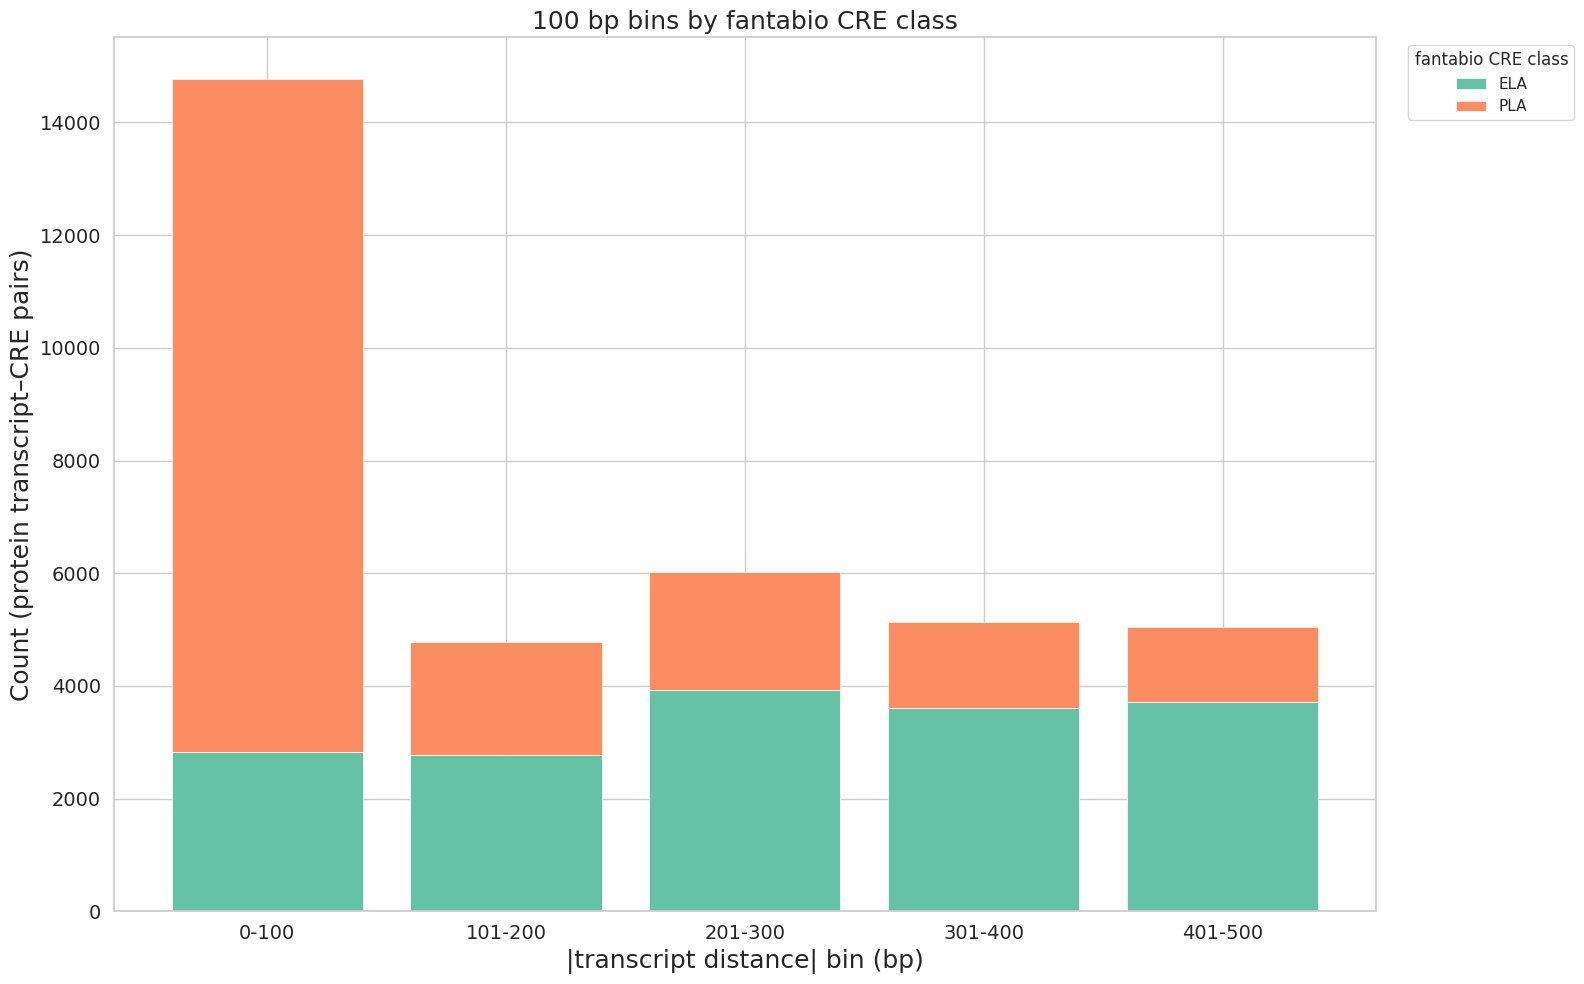

In [20]:
plot_df = up5p_protein_fantabio_cre_distance.to_pandas()

# 5 bins: 0-100, 101-200, ..., 401-500
bin_edges = [0, 101, 201, 301, 401, 501]
bin_labels = ["0-100", "101-200", "201-300", "301-400", "401-500"]

plot_df["distance_bin"] = pd.cut(
    plot_df["transcript_distance_abs"],
    bins=bin_edges,
    labels=bin_labels,
    right=False,
    include_lowest=True,
)

count_df = (
    plot_df.groupby(["distance_bin", "fantabio_cre_class"], observed=True)
    .size()
    .to_frame("count")
    .reset_index()
)

pivot_df = (
    count_df.pivot(index="distance_bin", columns="fantabio_cre_class", values="count")
    .fillna(0)
    .astype(int)
    .reindex(bin_labels)
)

classes = pivot_df.columns.tolist()
palette = sns.color_palette("Set2", n_colors=len(classes))
color_map = dict(zip(classes, palette))

sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(16, 10))

bottom = np.zeros(len(pivot_df))
x = np.arange(len(pivot_df.index))

for cls in classes:
    heights = pivot_df[cls].to_numpy()
    ax.bar(
        x,
        heights,
        bottom=bottom,
        label=cls,
        color=color_map[cls],
        edgecolor="white",
        linewidth=0.5,
    )
    bottom += heights

ax.set_xticks(x)
ax.set_xticklabels(pivot_df.index, fontsize=14)
ax.set_xlabel("|transcript distance| bin (bp)", fontsize=18)
ax.set_ylabel("Count (protein transcript–CRE pairs)", fontsize=18)
ax.set_title("100 bp bins by fantabio CRE class", fontsize=18)
ax.legend(title="fantabio CRE class", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.tick_params(axis="y", labelsize=14)

plt.tight_layout()
plt.show()

&nbsp;

&nbsp;

&nbsp;

## Other transcripts (except lncRNA and protein-coding) - CREs

In [21]:
# Select other transcripts
up5p_other_fantabio = up5p_fantabio.filter(
    (pl.col("transcript_type") != "lncRNA") & (pl.col("transcript_type") != "protein_coding")
).sort(
    "HN2",
    descending=True
)


print(f"up5p_other_fantabio ensembl transcript count: {up5p_other_fantabio.select('transcript_id').n_unique()}")
print(f"up5p_other_fantabio transcript-CRE pairs count: {up5p_other_fantabio.select(['transcript_id', 'cre_id']).n_unique()}")
display(up5p_other_fantabio)

up5p_other_fantabio ensembl transcript count: 6605
up5p_other_fantabio transcript-CRE pairs count: 18123


transcript_id,UP2,DOWN2,UNCHANGED2,HN2,UP2_stranded,DOWN2_stranded,UNCHANGED2_stranded,HN2_stranded,gene_symbol,HGNC_ID,transcript_type,gene_id,tags,strand,number_of_tags,RNACentral_ID,corrrespondence,polyA_features,gene_source,annotation_remarks,annotation_remark_count,cre_id,cre_chrom,cre_chrom_start,cre_chrom_end,cre_name,tss_nearest_transcript_ids,tss_nearest_transcript_distance,transcript_distance,screen_ccres,chip_atlas_antigens,silencerdbs,fantom5_cage_peaks,fantom5_enhancers,directionality,fantabio_cre_class,itemRgb,itemRgb_name
str,i64,i64,i64,i64,i64,i64,i64,i64,str,str,str,str,list[str],str,u32,str,str,list[str],str,list[str],u32,str,str,i64,str,str,list[str],str,i64,list[struct[2]],list[struct[3]],list[struct[5]],list[struct[2]],list[struct[1]],f64,str,str,str
"""ENST00000540260.1""",328,9,69,319,216,1,34,215,"""FKBP4""","""HGNC:3720""","""protein_coding_CDS_not_defined""","""ENSG00000004478.9""","[""non_canonical_TEC""]","""+""",1,null,null,null,"""ensembl_havana_gene_homo_sapie…","[""non canonical TEC""]",1,"""FCHS_86240""","""chr12""",2794544,"""2795205""","""cp3@FKBP4,cp1@ITFG2-AS1""","[""ENST00000839341.1"", ""ENST00000839340.1"", … ""DQ893668""]","""0""",452,"[{""EH38E1587359"",""pELS""}, {""EH38E2998737"",""PLS""}]","[{""HSF1"",3307,[{""SRX16646111"",3307}, {""SRX16646095"",3215}, … {""SRX3322007"",507}]}, {""ONECUT2"",2305,[{""SRX3927334"",2305}, {""SRX3927332"",713}, … {""SRX2731587"",570}]}, … {""FLI1"",508,[{""SRX117011"",508}]}]",null,"[{""hg19::chr12:2903742..2903763,-;hg_128965.1"",""hg_128965.1""}, {""hg19::chr12:2903775..2903794,-;hg_128966.1"",""hg_128966.1""}, … {""hg19::chr12:2904305..2904316,+;hg_123449.1"",""p6@FKBP4""}]",null,0.996397,"""PLA""","""204,0,0""","""red"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""ENST00000480008.1""",114,70,222,44,53,53,145,0,"""PHF10""","""HGNC:18250""","""retained_intron""","""ENSG00000130024.16""",[],"""-""",0,null,null,"[""polya_signal"", ""polya_site""]","""ensembl_havana_gene_homo_sapie…",null,0,"""FCHS_373152""","""chr6""",169724291,"""169724957""","""cp7@PHF10""","[""ENST00000339209.9"", ""NM_018288.4"", ""NM_133325.3""]","""0""",286,"[{""EH38E3749974"",""PLS""}, {""EH38E3749975"",""pELS""}]","[{""BCORL1"",2666,[{""SRX10184498"",2666}, {""SRX10184497"",2361}, {""SRX10184496"",1707}]}, {""CTCF"",2348,[{""SRX10976007"",2348}, {""SRX10975999"",2324}, … {""SRX14609196"",549}]}, … {""SMARCA4"",500,[{""SRX9562887"",500}]}]","[{""HS_00086002"",""Gastric"",""Stomach"",""Stomach"",""SVM""}]","[{""hg19::chr6:170124563..170124616,-;hg_76798.1"",""p1@PHF10""}, {""hg19::chr6:170124805..170124830,+;hg_71276.1"",""hg_71276.1""}, … {""hg19::chr6:170124890..170124910,+;hg_71278.1"",""hg_71278.1""}]",null,-0.831798,"""PLA""","""0,0,204""","""blue"""


In [22]:
# このデータフレームの行数 = protein transcript - CRE pair count になる
up5p_other_fantabio_cre_distance = up5p_other_fantabio.select(
    "transcript_id",
    "cre_id",
    "cre_name",
    "fantabio_cre_class",
    "transcript_distance"
).with_columns(
    pl.col("transcript_distance").abs().alias("transcript_distance_abs") # Point: 絶対値に変換
).unique()

display(up5p_other_fantabio_cre_distance)

transcript_id,cre_id,cre_name,fantabio_cre_class,transcript_distance,transcript_distance_abs
str,str,str,str,i64,i64
"""ENST00000504576.2""","""FCHS_324167""","""cp13@SLC12A7""","""ELA""",18,18
…,…,…,…,…,…
"""ENST00000648825.1""","""FCHS_105033""","""cp3@MED13L""","""ELA""",0,0


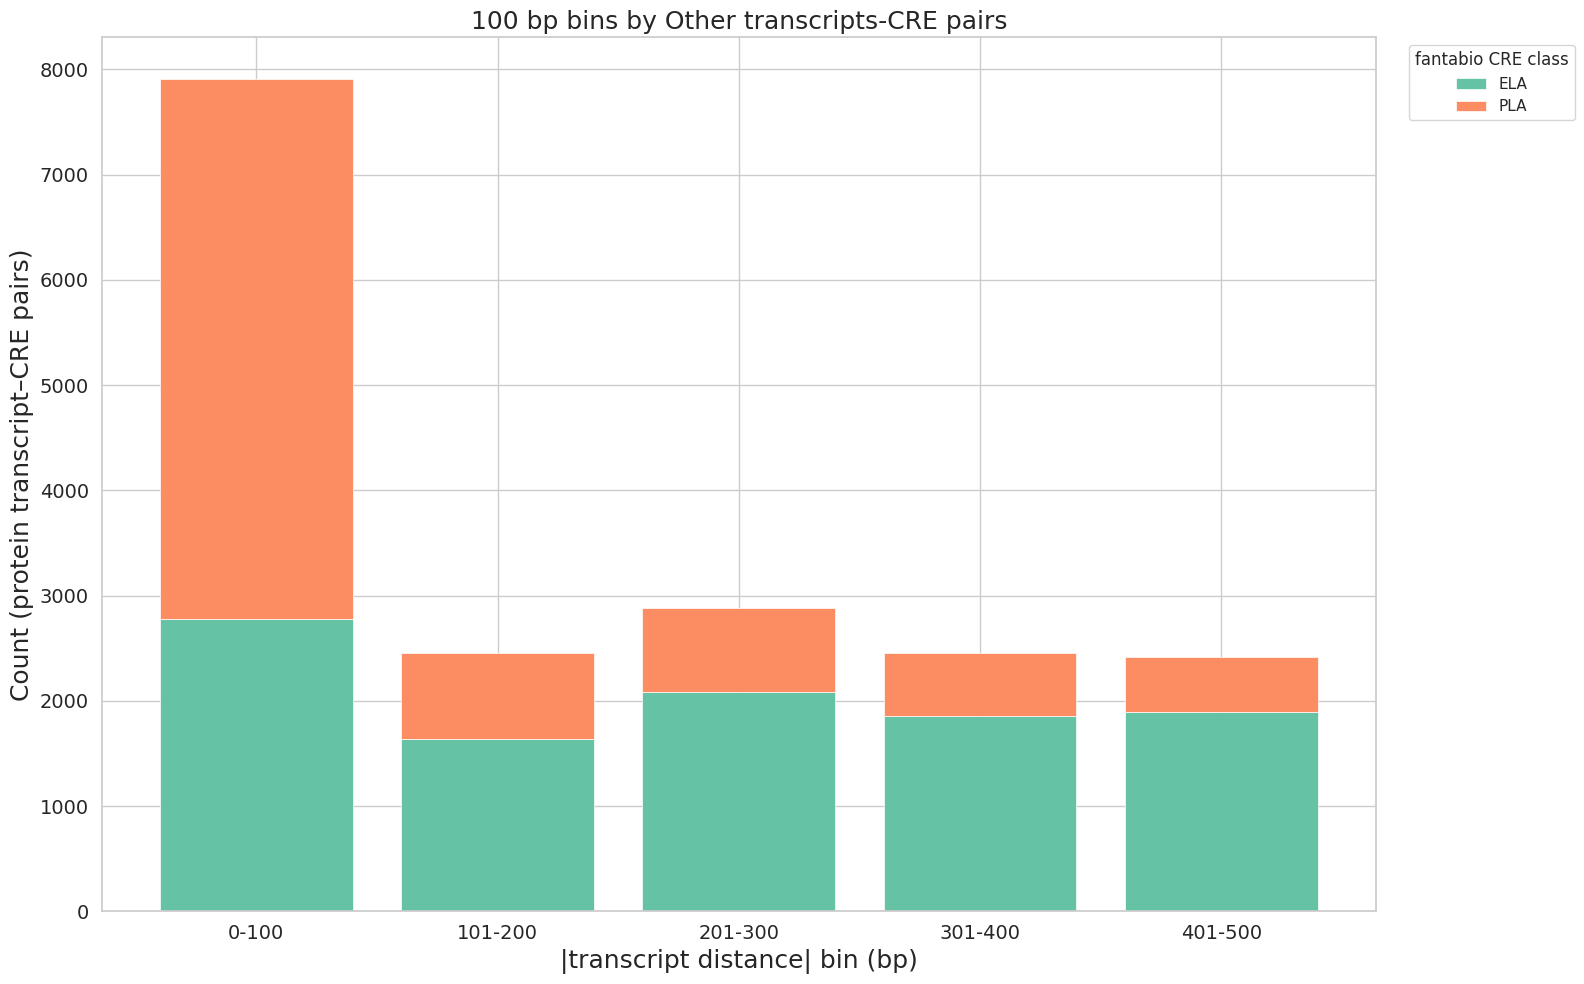

In [23]:
plot_df = up5p_other_fantabio_cre_distance.to_pandas()

# 5 bins: 0-100, 101-200, ..., 401-500
bin_edges = [0, 101, 201, 301, 401, 501]
bin_labels = ["0-100", "101-200", "201-300", "301-400", "401-500"]

plot_df["distance_bin"] = pd.cut(
    plot_df["transcript_distance_abs"],
    bins=bin_edges,
    labels=bin_labels,
    right=False,
    include_lowest=True,
)

count_df = (
    plot_df.groupby(["distance_bin", "fantabio_cre_class"], observed=True)
    .size()
    .to_frame("count")
    .reset_index()
)

pivot_df = (
    count_df.pivot(index="distance_bin", columns="fantabio_cre_class", values="count")
    .fillna(0)
    .astype(int)
    .reindex(bin_labels)
)

classes = pivot_df.columns.tolist()
palette = sns.color_palette("Set2", n_colors=len(classes))
color_map = dict(zip(classes, palette))

sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(16, 10))

bottom = np.zeros(len(pivot_df))
x = np.arange(len(pivot_df.index))

for cls in classes:
    heights = pivot_df[cls].to_numpy()
    ax.bar(
        x,
        heights,
        bottom=bottom,
        label=cls,
        color=color_map[cls],
        edgecolor="white",
        linewidth=0.5,
    )
    bottom += heights

ax.set_xticks(x)
ax.set_xticklabels(pivot_df.index, fontsize=14)
ax.set_xlabel("|transcript distance| bin (bp)", fontsize=18)
ax.set_ylabel("Count (protein transcript–CRE pairs)", fontsize=18)
ax.set_title("100 bp bins by Other transcripts-CRE pairs", fontsize=18)
ax.legend(title="fantabio CRE class", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.tick_params(axis="y", labelsize=14)

plt.tight_layout()
plt.show()

&nbsp;

&nbsp;

&nbsp;

&nbsp;

## Upsetplot

- lncRNA-CRE pairs, protein-coding transcript-CRE pairs, other transcript-CRE pairs で共通している CREを表現する

In [24]:
cre_contents = {
    "lncRNA proximal CREs (PLA)": up5p_lncRNA_fantabio.filter(pl.col("fantabio_cre_class") == "PLA").select("cre_id").unique().to_series().to_list(),
    "protein-coding proximal CREs (PLA)": up5p_protein_fantabio.filter(pl.col("fantabio_cre_class") == "PLA").select("cre_id").unique().to_series().to_list(),
    "lncRNA proximal CREs (ELA)": up5p_lncRNA_fantabio.filter(pl.col("fantabio_cre_class") == "ELA").select("cre_id").unique().to_series().to_list(),
    "protein-coding proximal CREs (ELA)": up5p_protein_fantabio.filter(pl.col("fantabio_cre_class") == "ELA").select("cre_id").unique().to_series().to_list(),
    # "other transcript proximal CREs": up5p_other_fantabio.select("cre_id").unique().to_series().to_list()
}

upset_data = from_contents(cre_contents)

upset_data.to_csv(
    f"../../out/fantabio/upsetplot/up5p_transcript_upset_data_v{Execute_date}.tsv",
    index=True,
    sep="\t"
)

display(upset_data)

/usr/local/lib/python3.13/site-packages/upsetplot/data.py:385: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)


id
lncRNA proximal CREs (PLA) protein-coding proximal CREs (PLA) lncRNA proximal CREs (ELA) protein-coding proximal CREs (ELA)             
True                       True                               False                      False                               FCHS_109491
                           False                              False                      False                                FCHS_77076
                                                                                         False                               FCHS_113500
                                                                                         False                               FCHS_353566
                                                                                         False                               FCHS_444875
...                                                                                                                                  ...
False                      False                              False                      True                                 FCHS_97561
                                                                                         True                                FCHS_541549
                                                                                         True                                FCHS_284888
                                                                                         True                                FCHS_160177
                                                                                         True                                 FCHS_74879

[25842 rows x 1 columns]

/usr/local/lib/python3.13/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  styles["linewidth"].fillna(1, inplace=True)
/usr/local/lib/python3.13/site-packages/upsetplot/plotting.py:796: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example,

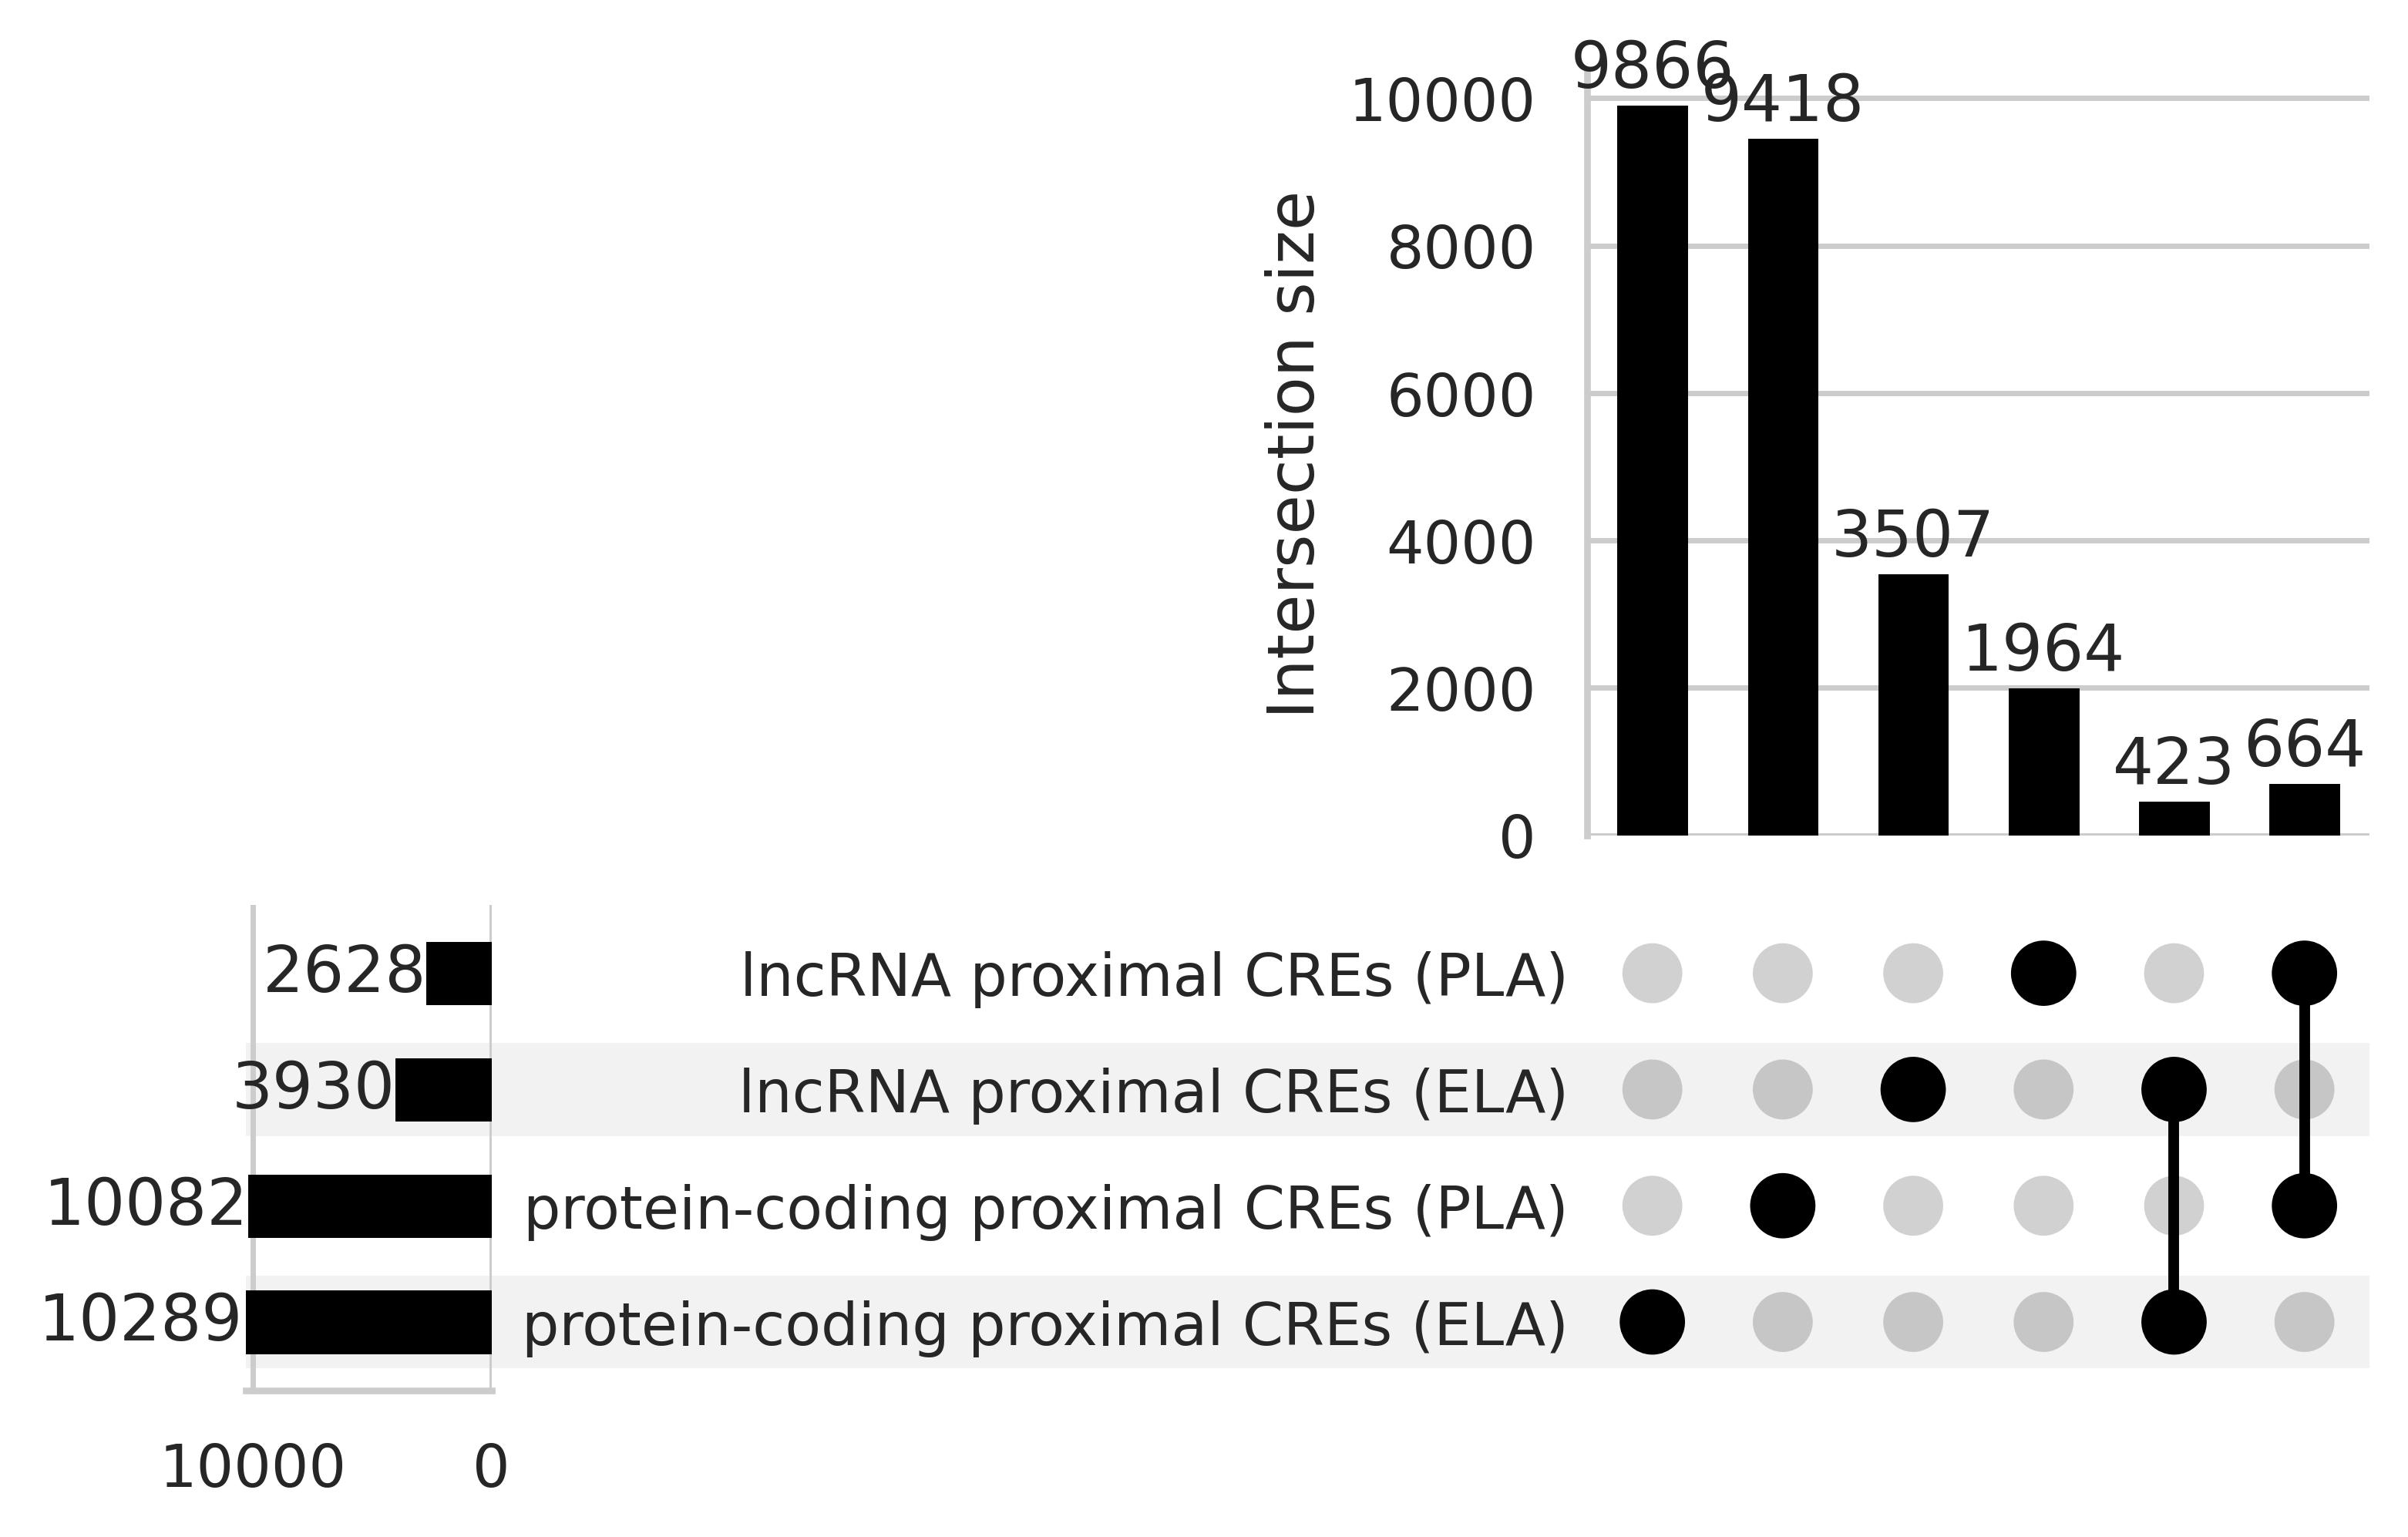

In [25]:
upset_plot = UpSet(
    upset_data,
    orientation='horizontal',
    show_counts="{:d}",
    subset_size='count',
    include_empty_subsets = False
)

fig = plt.figure(figsize=(14, 8), dpi=500)
upset_plot.plot(fig=fig)
plt.show()